# Prototype De-stacking

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import galsim
import ultranest as un
from colossus.halo import profile_nfw
from colossus.cosmology import cosmology as colossus_cosmology
import astropy.units as u
from astropy.cosmology import Planck18 
from astropy.constants import c, G
from scipy import integrate

In [2]:
Mhalo = 1e14
conc = 5.
zhalo = .3
OmegaM = 0.3
OmegaL = 0.7
galsim_cosmo = galsim.Cosmology()
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)

In [6]:
positions = [galsim.PositionD(0.,sep) for sep in np.logspace(0,np.log10(3600),360)]
shears = np.array([halo.getShear(position,1.0) for position in positions])

In [7]:
X = np.array([position.y for position in positions])
Y = shears[:,0]

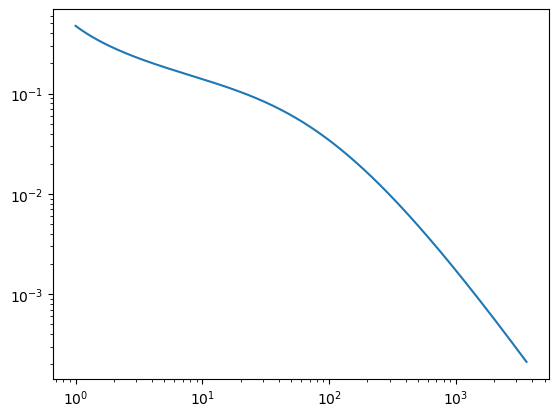

In [8]:
plt.plot(X,Y)
plt.xscale('log')
plt.yscale('log')

In [9]:
colossus_cosmology.setCosmology('planck18')
colossus_profile=profile_nfw.NFWProfile(M=1e14,c=5.,z=0.3,mdef='200m')

In [10]:
def critical_surface_density(z_l, z_s, cosmo):
    """
    Calculates the critical surface density for gravitational lensing.

    Args:
        z_l (float): Redshift of the lensing galaxy.
        z_s (float): Redshift of the background source.
        cosmology (astropy.cosmology.Cosmology): The cosmological model to use.

    Returns:
        astropy.units.Quantity: The critical surface density.
    """
    # Define angular diameter distances
    D_l = cosmo.angular_diameter_distance(z_l)
    D_s = cosmo.angular_diameter_distance(z_s)
    D_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s)

    # Formula for the critical surface density
    numerator = (c**2 * D_s)
    denominator = (4 * np.pi * G * D_l * D_ls)
    sigma_crit = numerator / denominator

    # Convert to standard units for surface density (e.g., Msun / sq pc)
    return sigma_crit.to(u.M_sun / u.pc**2)


# Define the redshifts for the lens and source
z_lens = 0.5   # Example lens redshift
z_source = 2.0 # Example source redshift

# Calculate the critical surface density
sigma_crit_value = critical_surface_density(z_lens, z_source, Planck18)

print(f"Lens redshift: {z_lens}")
print(f"Source redshift: {z_source}")
print(f"Critical surface density: {sigma_crit_value:.2f}")

# Example comparison: what if the lens is closer?
z_lens_closer = 0.25
sigma_crit_closer = critical_surface_density(z_lens_closer, z_source, Planck18)

print("\n--- Example with a closer lens ---")
print(f"Lens redshift: {z_lens_closer}")
print(f"Critical surface density: {sigma_crit_closer:.2f}")

Lens redshift: 0.5
Source redshift: 2.0
Critical surface density: 2023.50 solMass / pc2

--- Example with a closer lens ---
Lens redshift: 0.25
Critical surface density: 2484.12 solMass / pc2


In [11]:
def gamma_nfw_colossus(colossus_profile,z_source,cosmo,r):
    z_lens = colossus_profile.z
    Sigma_crit = critical_surface_density(z_lens, z_source, cosmo).value

    Sigma_bar = 1e-6*(integrate.quad(colossus_profile.surfaceDensity,1e-3,r))[0]/r
    Sigma = 1e-6*colossus_profile.surfaceDensity(r)
    gamma = (Sigma_bar - Sigma)/Sigma_crit
    #print(Sigma_crit,Sigma_bar,Sigma)
    return gamma

In [14]:
radii = np.logspace(-2,0,100)*1000
gammas=[gamma_nfw_colossus(colossus_profile,.7,Planck18,radius) for radius in radii]

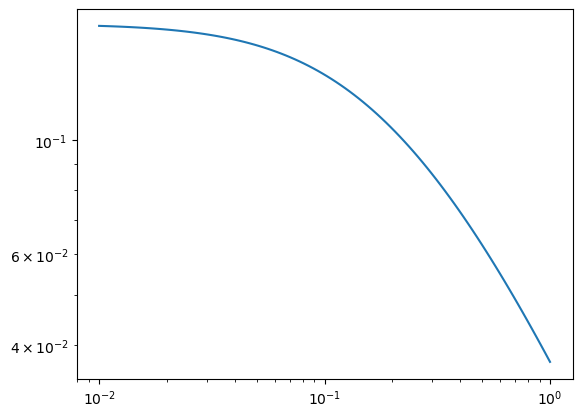

In [15]:
plt.plot(radii/1000,gammas)
plt.xscale('log')
plt.yscale('log')

In [30]:
colossus_profile.surfaceDensity?

Signature:
colossus_profile.surfaceDensity(
    r,
    interpolate=True,
    accuracy=0.0001,
    max_r_interpolate=100000000.0,
    max_r_integrate=1e+20,
)
Docstring:
The projected surface density at radius r.

The surface density is computed by projecting the 3D density along the line of sight,

.. math::
        \Sigma(R) = 2 \int_R^{\infty} \frac{r \rho(r)}{\sqrt{r^2-R^2}} dr

Parameters
----------
r: array_like
        Radius in physical kpc/h; can be a number or a numpy array.
interpolate: bool
        Use an interpolation table for density during the integration. This should make the
        evaluation somewhat faster, depending on how large the radius array is. 
accuracy: float
        The minimum accuracy of the integration.
max_r_interpolate: float
        The maximum radius in physical kpc/h to which the density profile is integrated when 
        using interpolating density.
max_r_integrate: float
        The maximum radius in physical kpc/h to which the density profile is